# Projekt - fáza č. 2

In [56]:
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import statsmodels.api as sm
import statsmodels.stats.api as sms
import scipy.stats as stats
from sklearn import preprocessing
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import TargetEncoder
sns.set_theme(style="whitegrid")

## Rozdelenie dát na trénovaciu a testovaciu množinu

Dáta delíme v pomere 80 % train a 20 % test. Od tohto kroku ďalej pracujeme iba s *train* množinou.

Každá jednotka (id_unit) má v dátach viac meraní (v priemere asi 7). Preto delíme podľa jednotiek, nie podľa riadkov - všetky merania jednej jednotky skončia buď v train, alebo v test. Keby sa tá istá jednotka dostala do oboch množín, model by si ju zapamätal a výsledky na teste by vyšli lepšie, než v skutočnosti sú.

Delenie je zároveň stratifikované na `fail`, takže podiel porúch (asi 12 %) je v oboch množinách rovnaký. `random_state` je pevne daný, aby bolo delenie vždy rovnaké.

In [57]:
from sklearn.model_selection import StratifiedGroupKFold

RANDOM_STATE = 42
TEST_SIZE = 0.20

data = pd.read_csv("./data/readings.csv", sep="\t")
data["id_unit"] = data["id_unit"].str[1:].astype(int)
data.loc[data["id_unit"] > 2000, "id_unit"] -= 90000

sgkf = StratifiedGroupKFold(n_splits=round(1 / TEST_SIZE), shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(sgkf.split(data, data["Failure"], groups=data["id_unit"]))
train = data.iloc[train_idx].copy()
test = data.iloc[test_idx].copy()

assert set(train["id_unit"]).isdisjoint(test["id_unit"])
assert len(train) + len(test) == len(data)

for nazov, cast in [("cele data", data), ("train", train), ("test", test)]:
    print(nazov, "- riadky:", len(cast), "- jednotky:", cast["id_unit"].nunique(),
          "- podiel Failure=1:", round(cast["Failure"].mean(), 4))

train.to_csv("./data/Ciste_data/train_raw.csv", index=False, encoding="utf-8-sig")
test.to_csv("./data/Ciste_data/test_raw.csv", index=False, encoding="utf-8-sig")

cele data - riadky: 14052 - jednotky: 1999 - podiel Failure=1: 0.1188
train - riadky: 11244 - jednotky: 1597 - podiel Failure=1: 0.1189
test - riadky: 2808 - jednotky: 402 - podiel Failure=1: 0.1186


In [58]:
train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11244 entries, 1 to 14051
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_unit             11244 non-null  int64  
 1   cycle_ts            11244 non-null  object 
 2   currentMotor        11244 non-null  float64
 3   dp_filter           10833 non-null  float64
 4   oilTemperature      11244 non-null  float64
 5   pressure_reservoir  11244 non-null  float64
 6   rmsVibration        10820 non-null  float64
 7   Flowmeter           11244 non-null  float64
 8   dischargeDewpoint   11244 non-null  float64
 9   Failure             11244 non-null  int64  
dtypes: float64(7), int64(2), object(1)
memory usage: 966.3+ KB


In [59]:
train.head()

,id_unit,cycle_ts,currentMotor,dp_filter,oilTemperature,pressure_reservoir,rmsVibration,Flowmeter,dischargeDewpoint,Failure
1,1922,2023-10-05,5.20071,14.68177,36.67755,8.84326,6.40699,26.62476,7.60072,1
2,548,2023-10-18,5.56161,44.22325,43.50675,8.03135,4.30464,26.39225,5.25673,0
4,298,04 Oct 2023,5.11036,29.84890,64.71004,9.78952,2.82960,33.75524,11.50507,0
5,1522,12 Dec 2023,2.47593,NaN,63.34515,8.66470,5.10853,27.65622,5.79981,1
6,748,2023/04/23,6.60443,18.84023,40.67046,8.61937,NaN,25.53233,3.43388,1


In [60]:
import numpy as np
from sklearn.impute import KNNImputer

def parse_dates(col):
    s = pd.Series(col).astype(str).str.strip()
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    for fmt in ["%Y-%m-%d", "%Y/%m/%d", "%d %b %Y",
                "%m/%d/%Y, %H:%M:%S", "%Y-%m-%d %H:%M:%S"]:
        out = out.fillna(pd.to_datetime(s, format=fmt, errors="coerce"))
    return out

def clean_gateways(df):
    df = df.copy()
    rename_map = {
        "Lon": "lon",
        "idDepot": "id_deport",
        "macAddress": "mac_addr",
        "versionFirmware": "version_firmware",
        "Vendor": "vendor",
        "Technician": "technician",
        "idUnit": "id_unit",
    }
    df = df.rename(columns=rename_map)

    if "gateway_id" not in df.columns:
        df = df.reset_index()
        if "gateway_id" not in df.columns:
            df = df.rename(columns={df.columns[0]: "gateway_id"})

    df["gateway_id"] = pd.to_numeric(
        df["gateway_id"].astype(str).str.replace(r"\D", "", regex=True), errors="coerce"
    ).astype("Int64")

    if "id_unit" in df.columns:
        df["id_unit"] = pd.to_numeric(df["id_unit"], errors="coerce").astype("Int64")

    for c in ["install_date", "seen_last"]:
        df[c] = parse_dates(df[c])
    return df

def clean_readings(df):
    df = df.copy()
    rename_map = {
        "currentMotor": "curr_motor",
        "oilTemperature": "oil_temp",
        "pressure_reservoir": "press_reserv",
        "rmsVibration": "rms_vibration",
        "Flowmeter": "flow",
        "dischargeDewpoint": "dis_dewp",
        "Failure": "fail",
    }
    df = df.rename(columns=rename_map)

    df["id_unit"] = (
        df["id_unit"].astype(str).str.strip().str.replace(r"^U", "", regex=True).str.replace(r"\D", "", regex=True).replace("", np.nan)
    )
    df["id_unit"] = pd.to_numeric(df["id_unit"], errors="coerce")
    bad = df["id_unit"] > 2000
    if bad.any():
        df.loc[bad, "id_unit"] = df.loc[bad, "id_unit"] - 90000
    df["id_unit"] = df["id_unit"].astype("Int64")

    df["cycle_ts"] = parse_dates(df["cycle_ts"])

    for col, bad_value in {"oil_temp": -999, "curr_motor": 99, "dp_filter": 120}.items():
        if col in df.columns:
            df[col] = df[col].replace(bad_value, np.nan)

    sensor_cols = ["curr_motor", "dp_filter", "oil_temp", "press_reserv", "rms_vibration", "flow", "dis_dewp"]
    agg = {c: "mean" for c in sensor_cols}
    agg["fail"] = "max"
    df = df.groupby(["id_unit", "cycle_ts"], as_index=False).agg(agg)
    return df

def clean_units(df):
    df = df.copy()
    rename_map = {
        "idDepot": "id_deport",
        "year_commission": "y_commission",
        "serviceHours": "serv_hours",
        "serial_number": "serial_num",
    }
    df = df.rename(columns=rename_map)

    class_map = {
        "1": 1, "l": 1, "light": 1,
        "2": 2, "med": 2, "n": 2, "normal": 2,
        "3": 3, "h": 3, "heavy": 3,
    }
    if "duty_class" in df.columns:
        raw = df["duty_class"]
        df["duty_class"] = (
            df["duty_class"].astype(str).str.strip().str.lower().map(class_map).astype("Int64")
        )
        assert df["duty_class"].isna().sum() == raw.isna().sum()
    df["overhaul_last"] = parse_dates(df["overhaul_last"])
    df["serv_hours"] = pd.to_numeric(df["serv_hours"], errors="coerce")
    return df

def clean_project_data(gateways, readings, units):
    return clean_gateways(gateways), clean_readings(readings), clean_units(units)

def impute_serv_hours(units):
    u = units.copy()
    u[["y_commission", "serv_hours"]] = KNNImputer(n_neighbors=5).fit_transform(
        u[["y_commission", "serv_hours"]].astype(float))
    return u

WINSOR = {"dp_filter": (0.05, 0.95), "rms_vibration": (0.05, 0.95), "dis_dewp": (0.05, 0.95),
          "press_reserv": (0.05, 0.95), "oil_temp": (0.05, 0.95), "flow": (0.05, 0.95)}

def impute_and_winsorize(readings, limits=WINSOR):
    df = readings.copy()
    for c in ["dp_filter", "rms_vibration"]:
        df[c] = df[c].fillna(df.groupby("fail")[c].transform("median"))
    for c in ["curr_motor", "oil_temp"]:
        df[c] = df[c].fillna(df[c].median())
    for c, (lo, hi) in limits.items():
        df[c] = df[c].clip(df[c].quantile(lo), df[c].quantile(hi))
    return df

def encodeData(data):
    data = data.copy()
    t = pd.to_datetime(data["cycle_ts"], errors="coerce")
    data["cycle_month"] = t.dt.month
    data["cycle_dow"] = t.dt.dayofweek
    data["cycle_hour"] = t.dt.hour
    data["cycle_doy"] = t.dt.dayofyear
    if "y_commission" in data.columns:
        data["unit_age_years"] = t.dt.year - data["y_commission"]
    return data

def build_dataset(gateways, readings, units):
    g, r, u = clean_project_data(gateways, readings, units)
    u = impute_serv_hours(u)
    r = impute_and_winsorize(r)
    df = (r.merge(u.drop(columns="id_deport"), on="id_unit", how="left")
            .merge(g.dropna(subset=["id_unit"]).drop_duplicates("id_unit").drop(columns="id_deport"),
                   on="id_unit", how="left", suffixes=("", "_gw")))
    return encodeData(df)

In [61]:
gateways_c = clean_gateways(pd.read_csv("./data/gateways.csv", sep=";", index_col=13))
units_c    = clean_units(pd.read_csv("./data/units.csv", sep=",", index_col=5))

gateways_c = (gateways_c.dropna(subset=["id_unit"]).drop_duplicates("id_unit")
                        .drop(columns="id_deport"))
gateways_c["id_unit"] = gateways_c["id_unit"].astype("int64")

In [62]:
CAT_COLS  = ["hardware_model", "version_firmware"]
DROP_COLS = ["gateway_id", "mac_addr", "ipv4", "serial_num",
             "install_date", "seen_last", "overhaul_last", "cycle_ts",
             "vendor", "technician"]

def make_numeric_frame(readings_raw):
    r = clean_readings(readings_raw)
    df = (r.merge(units_c, on="id_unit", how="left", validate="m:1")
           .merge(gateways_c, on="id_unit", how="left", validate="m:1"))
    assert len(df) == len(r), "merge zmenil pocet riadkov"

    t = df["cycle_ts"]
    df["days_since_install"] = (t - df["install_date"]).dt.days
    df["days_since_overhaul"] = (t - df["overhaul_last"]).dt.days
    df["unit_age_years"] = t.dt.year - df["y_commission"]
    df["cycle_month"] = t.dt.month
    df["cycle_dow"] = t.dt.dayofweek
    df["cycle_doy"] = t.dt.dayofyear
    df["seen_before_install"] = (df["seen_last"] < df["install_date"]).astype(int)
    for c in ["dp_filter", "rms_vibration"]:
        df[c + "_missing"] = df[c].isna().astype(int)

    df = df.drop(columns=DROP_COLS)
    for c in df.columns:
        if str(df[c].dtype) in ("Int64", "Float64"):
            df[c] = df[c].astype("float64")
    return df

train_df = make_numeric_frame(pd.read_csv("./data/Ciste_data/train_raw.csv"))
test_df  = make_numeric_frame(pd.read_csv("./data/Ciste_data/test_raw.csv"))

In [63]:
encoder = ColumnTransformer(
    [("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.05,
                           sparse_output=False), CAT_COLS),
     ("depot", TargetEncoder(target_type="binary", smooth="auto", cv=5, random_state=42),
      ["id_deport"])],
    remainder="passthrough", verbose_feature_names_out=False,
).set_output(transform="pandas")

train_num = encoder.fit_transform(train_df, train_df["fail"])
test_num  = encoder.transform(test_df)

c:\Users\stevo\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


In [64]:
assert train_num.select_dtypes(exclude="number").empty
assert list(train_num.columns) == list(test_num.columns)
print(train_num.shape, test_num.shape)
print(train_num.isna().sum()[lambda s: s > 0])

train_num.to_csv("./data/Ciste_data/train_numeric.csv", index=False)
test_num.to_csv("./data/Ciste_data/test_numeric.csv", index=False)

(11016, 33) (2756, 33)
curr_motor         7
dp_filter        406
oil_temp          50
rms_vibration    413
serv_hours       543
dtype: int64


In [65]:
train_num.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11016 entries, 0 to 11015
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   hardware_model_GWX-100   11016 non-null  float64
 1   hardware_model_GWX-200   11016 non-null  float64
 2   hardware_model_GWX-300   11016 non-null  float64
 3   hardware_model_NODE-7    11016 non-null  float64
 4   hardware_model_NODE-9    11016 non-null  float64
 5   version_firmware_v1.2.5  11016 non-null  float64
 6   version_firmware_v2.7.0  11016 non-null  float64
 7   version_firmware_v3.4.1  11016 non-null  float64
 8   id_deport                11016 non-null  float64
 9   id_unit                  11016 non-null  float64
 10  curr_motor               11009 non-null  float64
 11  dp_filter                10610 non-null  float64
 12  oil_temp                 10966 non-null  float64
 13  press_reserv             11016 non-null  float64
 14  rms_vibration         

## Škálovanie a transformácie

14 spojitych atributov, 17 ostatnych


,min,max,std,NaN,sikmost
curr_motor,0.44,10.00,1.82,7,0.19
dp_filter,7.26,116.31,11.32,406,1.87
oil_temp,15.00,95.00,11.91,50,-0.03
press_reserv,6.50,10.50,0.60,0,-0.01
rms_vibration,0.50,14.00,1.65,413,1.68
flow,15.00,40.00,3.99,0,-0.00
dis_dewp,-5.12,23.90,3.49,0,0.01
serv_hours,1303.00,45000.00,8722.40,543,1.32
signal_dbm,-105.90,-40.00,9.99,0,-0.04
lat,38.60,41.70,0.91,0,-0.01


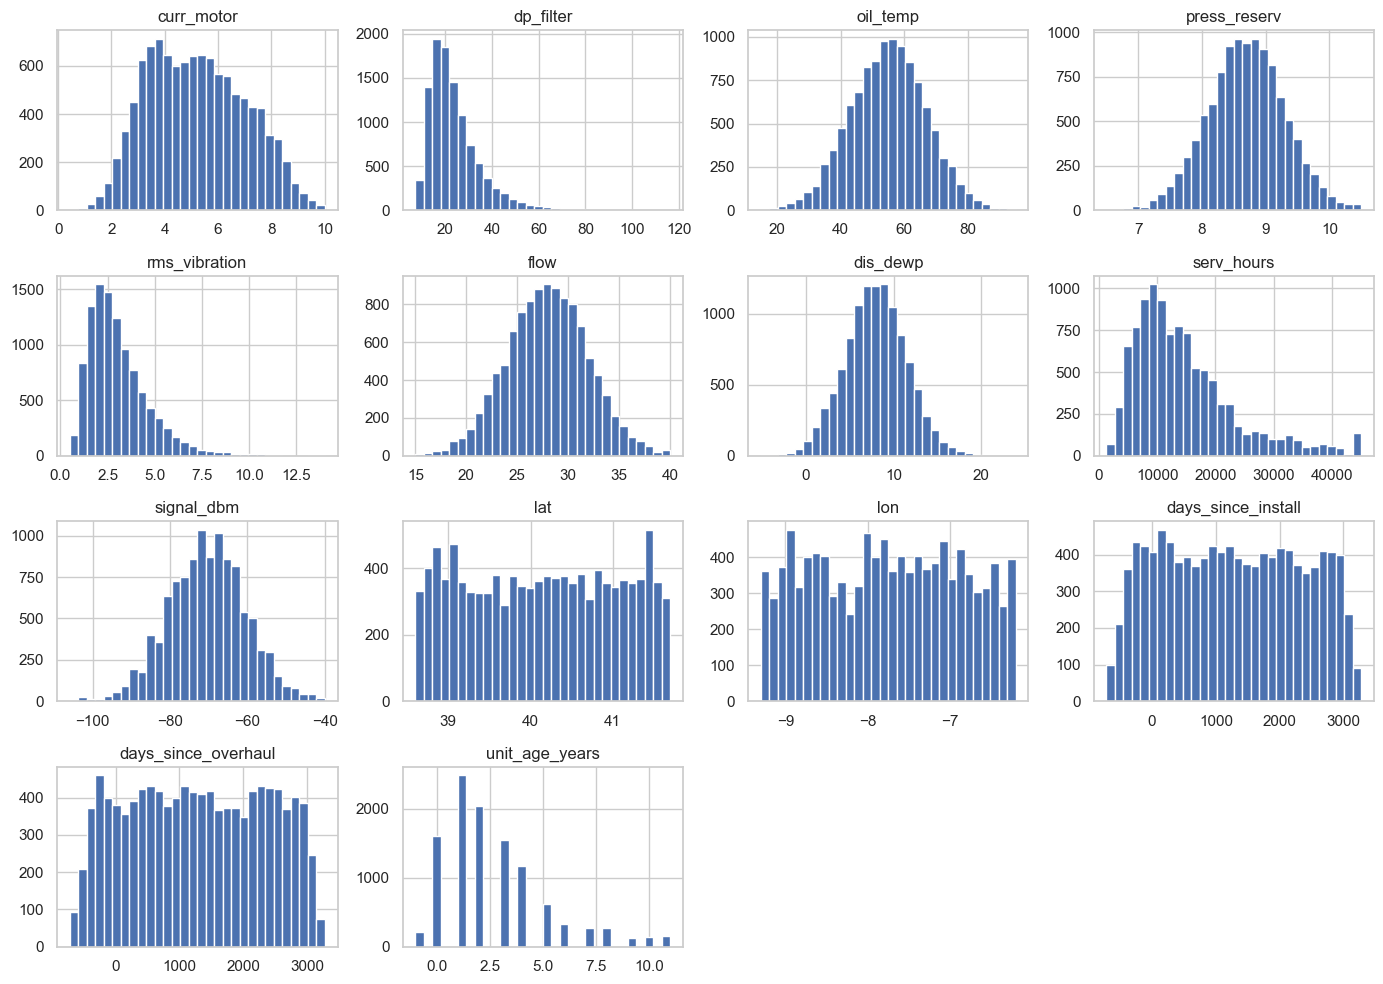

In [66]:
from scipy.stats import skew
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, PowerTransformer, QuantileTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, cross_validate

# train_num je vystup z 2.1 B; id_unit a fail nie su atributy
X_train = train_num.drop(columns=["fail", "id_unit"])
y_train = train_num["fail"]
groups = train_num["id_unit"]

# spojite atributy - tie budeme upravovat; one-hot, 0/1 priznaky, duty_class, depo a cyklicke casove atributy ostavaju
spojite = ["curr_motor", "dp_filter", "oil_temp", "press_reserv", "rms_vibration", "flow", "dis_dewp",
           "serv_hours", "signal_dbm", "lat", "lon", "days_since_install", "days_since_overhaul", "unit_age_years"]
ostatne = [c for c in X_train.columns if c not in spojite]
print(len(spojite), "spojitych atributov,", len(ostatne), "ostatnych")

popis = pd.DataFrame({"min": X_train[spojite].min(), "max": X_train[spojite].max(),
                      "std": X_train[spojite].std(), "NaN": X_train[spojite].isna().sum(),
                      "sikmost": X_train[spojite].apply(lambda s: skew(s.dropna()))}).round(2)
display(popis)
X_train[spojite].hist(bins=30, figsize=(14, 10))
plt.tight_layout(); plt.show()

In [67]:
def hranice_sigma(s):
    m, sd = s.mean(), s.std()
    return m - 3 * sd, m + 3 * sd

def hranice_iqr(s):
    q25, q75 = s.quantile(0.25), s.quantile(0.75)
    iqr = q75 - q25
    return q25 - 1.5 * iqr, q75 + 1.5 * iqr

pocty = {}
for c in spojite:
    s = X_train[c].dropna()
    pocty[c] = {}
    for nazov, f in [("3 sigma", hranice_sigma), ("IQR 1.5", hranice_iqr)]:
        lo, hi = f(s)
        pocty[c][nazov] = int(((s < lo) | (s > hi)).sum())
    lo, hi = s.quantile(0.05), s.quantile(0.95)
    pocty[c]["mimo 5-95 %"] = int(((s < lo) | (s > hi)).sum())
display(pd.DataFrame(pocty).T)


class OutlierClipper(BaseEstimator, TransformerMixin):
    # Nahradi odlahle hodnoty hranicnymi - hranice sa naucia na train a pouziju aj na test
    def __init__(self, method="iqr"):
        self.method = method   # "iqr" (1.5 x IQR), "sigma" (3 sigma) alebo "percentile" (5. a 95. percentil)
    def fit(self, X, y=None):
        if hasattr(X, "columns"):
            self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        X = np.asarray(X, dtype=float)
        if self.method == "iqr":
            q25, q75 = np.nanpercentile(X, 25, axis=0), np.nanpercentile(X, 75, axis=0)
            self.lo_, self.hi_ = q25 - 1.5 * (q75 - q25), q75 + 1.5 * (q75 - q25)
        elif self.method == "sigma":
            m, sd = np.nanmean(X, axis=0), np.nanstd(X, axis=0)
            self.lo_, self.hi_ = m - 3 * sd, m + 3 * sd
        else:
            self.lo_, self.hi_ = np.nanpercentile(X, 5, axis=0), np.nanpercentile(X, 95, axis=0)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)
    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features if input_features is not None else self.feature_names_in_, dtype=object)

,3 sigma,IQR 1.5,mimo 5-95 %
curr_motor,0,0,1102
dp_filter,181,464,1062
oil_temp,26,76,1098
press_reserv,14,98,1102
rms_vibration,165,365,1062
flow,29,79,1102
dis_dewp,36,105,1102
serv_hours,189,525,1037
signal_dbm,57,86,1084
lat,0,0,1091


In [68]:
cv = GroupKFold(n_splits=5)      # delime podla jednotiek, aby sa jedna jednotka neobjavila v train aj validacii
modely = {
    "LogReg": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "kNN": KNeighborsClassifier(n_neighbors=25),
    "RandomForest": RandomForestClassifier(n_estimators=100, min_samples_leaf=5, class_weight="balanced",
                                           random_state=42, n_jobs=1),
}

def zostav(clip=None, imputer="median", trans=None, scaler=None):
    kroky = []
    if clip:
        kroky.append(("clip", OutlierClipper(method=clip)))
    kroky.append(("imputer", KNNImputer(n_neighbors=5) if imputer == "knn" else SimpleImputer(strategy="median")))
    if trans == "yeo-johnson":
        kroky.append(("trans", PowerTransformer(method="yeo-johnson", standardize=False)))
    elif trans == "quantile":
        kroky.append(("trans", QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=42)))
    if scaler:
        kroky.append(("scaler", {"standard": StandardScaler(), "minmax": MinMaxScaler(), "robust": RobustScaler()}[scaler]))
    return ColumnTransformer([("spojite", Pipeline(kroky), spojite)], remainder="passthrough",
                             verbose_feature_names_out=False)

def porovnaj(varianty):     # varianty: {nazov: dict(...)}; vrati ROC-AUC, F1 a recall zo CV
    riadky = []
    for nazov, nastavenie in varianty.items():
        for m_nazov, model in modely.items():
            pipe = Pipeline([("prep", zostav(**nastavenie)), ("model", model)])
            s = cross_validate(pipe, X_train, y_train, groups=groups, cv=cv,
                               scoring=["roc_auc", "f1", "recall"], n_jobs=-1)
            riadky.append({"variant": nazov, "model": m_nazov, "ROC-AUC": s["test_roc_auc"].mean(),
                           "F1": s["test_f1"].mean(), "recall": s["test_recall"].mean()})
    vys = pd.DataFrame(riadky).pivot(index="variant", columns="model", values=["ROC-AUC", "F1", "recall"]).round(3)
    return vys.reindex(list(varianty))

def sikmost_po(nastavenie):
    Z = zostav(**nastavenie).fit_transform(X_train)[:, :len(spojite)]
    return pd.Series(skew(Z), index=spojite).round(2)

In [69]:
vys_clip = porovnaj({
    "bez orezania": dict(scaler="standard"),
    "3 sigma": dict(clip="sigma", scaler="standard"),
    "IQR 1.5": dict(clip="iqr", scaler="standard"),
    "5. a 95. percentil": dict(clip="percentile", scaler="standard"),
})
display(vys_clip)

ROC-AUC                         F1                      \
model               LogReg RandomForest    kNN LogReg RandomForest    kNN   
variant                                                                     
bez orezania         0.806        0.791  0.583  0.416        0.459  0.000   
3 sigma              0.806        0.792  0.586  0.416        0.459  0.000   
IQR 1.5              0.806        0.790  0.585  0.415        0.457  0.002   
5. a 95. percentil   0.806        0.791  0.588  0.411        0.458  0.002   

                   recall                      
model              LogReg RandomForest    kNN  
variant                                        
bez orezania        0.691        0.487  0.000  
3 sigma             0.693        0.489  0.000  
IQR 1.5             0.688        0.489  0.001  
5. a 95. percentil  0.684        0.483  0.001

In [70]:
vys_imp = porovnaj({
    "median": dict(clip="iqr", imputer="median", scaler="standard"),
    "KNN": dict(clip="iqr", imputer="knn", scaler="standard"),
})
display(vys_imp)

ROC-AUC                         F1                     recall  \
model    LogReg RandomForest    kNN LogReg RandomForest    kNN LogReg   
variant                                                                 
median    0.806        0.790  0.585  0.415        0.457  0.002  0.688   
KNN       0.806        0.791  0.584  0.414        0.458  0.002  0.688   

                             
model   RandomForest    kNN  
variant                      
median         0.489  0.001  
KNN            0.484  0.001

In [71]:
vys_scaler = porovnaj({
    "bez skalovania": dict(clip="iqr"),
    "StandardScaler": dict(clip="iqr", scaler="standard"),
    "MinMaxScaler": dict(clip="iqr", scaler="minmax"),
    "RobustScaler": dict(clip="iqr", scaler="robust"),
})
display(vys_scaler)

# rozsah hodnot po skalovani (skalovanie meni mierku, nie tvar)
rozsah = {}
for nazov, sc in [("bez skalovania", None), ("Standard", "standard"), ("MinMax", "minmax"), ("Robust", "robust")]:
    Z = zostav(clip="iqr", scaler=sc).fit_transform(X_train)[:, :len(spojite)]
    rozsah[nazov] = {"min": Z.min().round(2), "max": Z.max().round(2), "max |sikmost|": np.abs(skew(Z)).max().round(2)}
display(pd.DataFrame(rozsah).T)

ROC-AUC                         F1                     recall  \
model           LogReg RandomForest    kNN LogReg RandomForest    kNN LogReg   
variant                                                                        
bez skalovania   0.767         0.79  0.547  0.360        0.457  0.000  0.694   
StandardScaler   0.806         0.79  0.585  0.415        0.457  0.002  0.688   
MinMaxScaler     0.806         0.79  0.586  0.416        0.457  0.000  0.688   
RobustScaler     0.806         0.79  0.588  0.415        0.457  0.000  0.689   

                                    
model          RandomForest    kNN  
variant                             
bez skalovania        0.489  0.000  
StandardScaler        0.489  0.001  
MinMaxScaler          0.489  0.000  
RobustScaler          0.489  0.000

,min,max,max |sikmost|
bez skalovania,-716.00,33632.30,0.98
Standard,-2.74,2.72,0.98
MinMax,0.00,1.00,0.98
Robust,-2.02,2.20,0.98


**Škálovanie.** Bez neho je rozsah hodnôt od −716 do 33 632. Všetky tri scalery ho zmenšia (Standard −2.7 až 2.7, MinMax 0 až 1, Robust −2.0 až 2.2) a nemenia tvar (najväčšia šikmosť zostáva 0,98). 
* Efekt je jasný: logistická regresia 0,758 na 0,806 a kNN 0,547 na cca 0,585 ROC-AUC. Random Forest sa nezmení (0,79), čo sedí s tým, že stromy mierku nepotrebujú. Scalery sa medzi sebou nelíšia, preto si vyberame **`StandardScaler`**.

ROC-AUC                         F1               \
model                    LogReg RandomForest    kNN LogReg RandomForest   
variant                                                                   
bez transformacie         0.806        0.790  0.585  0.415        0.457   
Yeo-Johnson               0.808        0.790  0.592  0.411        0.457   
Quantile (s orezanim)     0.802        0.790  0.580  0.407        0.457   
Quantile (bez orezania)   0.806        0.792  0.580  0.410        0.459   

                               recall                      
model                      kNN LogReg RandomForest    kNN  
variant                                                    
bez transformacie        0.002  0.688        0.489  0.001  
Yeo-Johnson              0.002  0.687        0.489  0.001  
Quantile (s orezanim)    0.002  0.675        0.489  0.001  
Quantile (bez orezania)  0.002  0.682        0.488  0.001

,bez transformacie,Yeo-Johnson,Quantile (s orezanim),Quantile (bez orezania)
dp_filter,0.93,0.01,1.77,0.00
rms_vibration,0.87,0.01,1.67,0.08
serv_hours,0.98,-0.01,1.80,0.87
unit_age_years,0.96,-0.02,0.71,-0.20


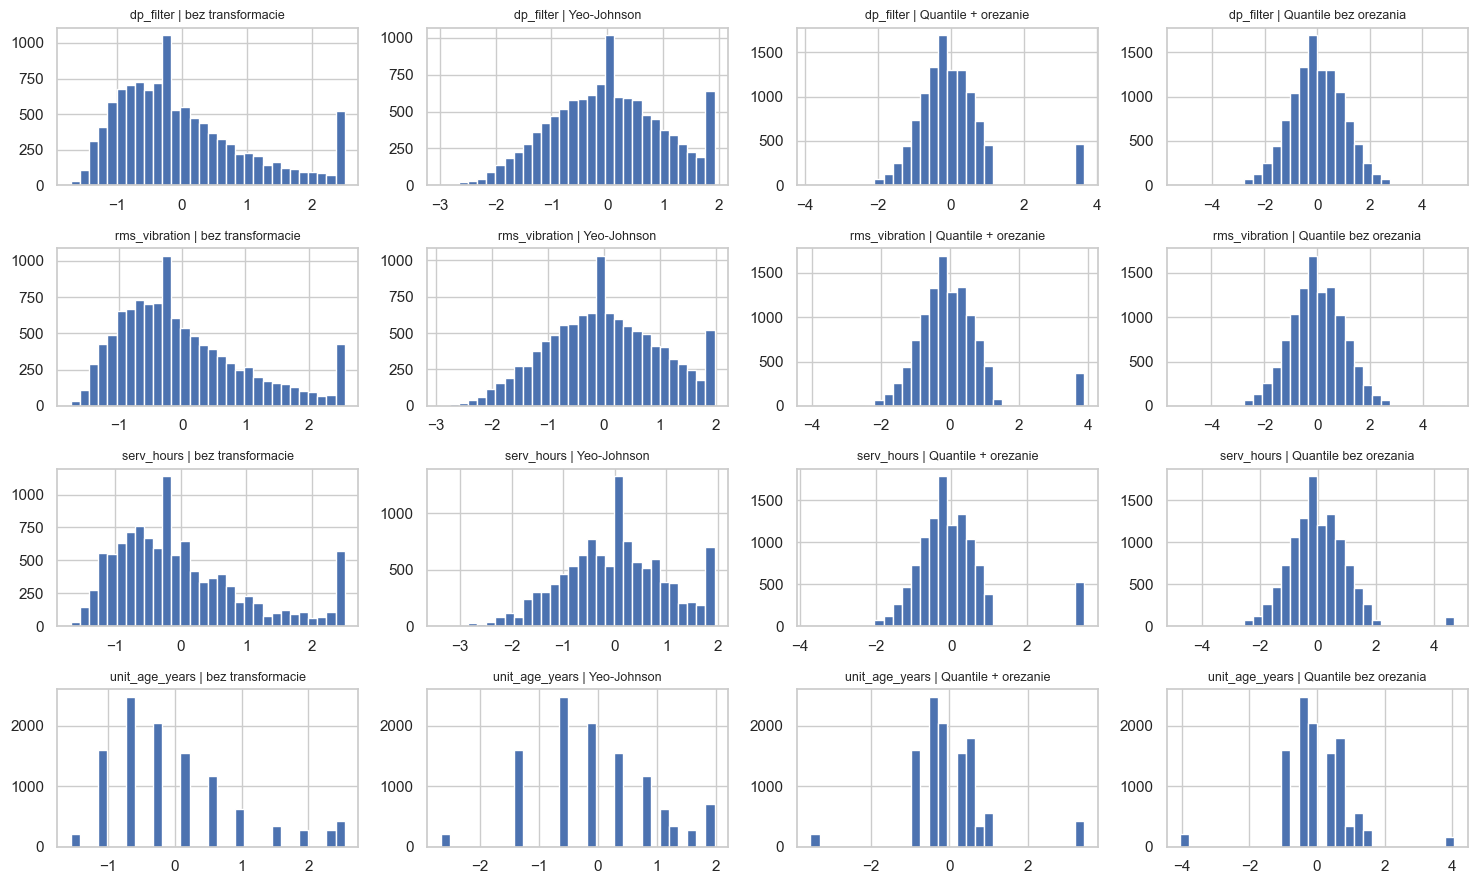

In [72]:
vys_trans = porovnaj({
    "bez transformacie": dict(clip="iqr", scaler="standard"),
    "Yeo-Johnson": dict(clip="iqr", trans="yeo-johnson", scaler="standard"),
    "Quantile (s orezanim)": dict(clip="iqr", trans="quantile", scaler="standard"),
    "Quantile (bez orezania)": dict(trans="quantile", scaler="standard"),
})
display(vys_trans)

# sikmost a tvar rozdelenia najsikmejsich atributov
sikme = ["dp_filter", "rms_vibration", "serv_hours", "unit_age_years"]
tab = pd.DataFrame({"bez transformacie": sikmost_po(dict(clip="iqr", scaler="standard")),
                    "Yeo-Johnson": sikmost_po(dict(clip="iqr", trans="yeo-johnson", scaler="standard")),
                    "Quantile (s orezanim)": sikmost_po(dict(clip="iqr", trans="quantile", scaler="standard")),
                    "Quantile (bez orezania)": sikmost_po(dict(trans="quantile", scaler="standard"))}).loc[sikme]
display(tab)

fig, ax = plt.subplots(len(sikme), 4, figsize=(15, 9))
for j, (nazov, nast) in enumerate([("bez transformacie", dict(clip="iqr", scaler="standard")),
                                   ("Yeo-Johnson", dict(clip="iqr", trans="yeo-johnson", scaler="standard")),
                                   ("Quantile + orezanie", dict(clip="iqr", trans="quantile", scaler="standard")),
                                   ("Quantile bez orezania", dict(trans="quantile", scaler="standard"))]):
    Z = zostav(**nast).fit_transform(X_train)[:, :len(spojite)]
    for i, c in enumerate(sikme):
        ax[i, j].hist(Z[:, spojite.index(c)], bins=30)
        ax[i, j].set_title(f"{c} | {nazov}", fontsize=9)
plt.tight_layout(); plt.show()

**Transformácie.** Yeo-Johnson vyrovná šikmé atribúty takmer dokonale (`dp_filter` 0,93 -> 0,01; `rms_vibration` 0,87 -> 0,01; `serv_hours` 0,98 -> −0,01; `unit_age_years` 0,96 -> −0,02) a zvláda záporné hodnoty (`days_since_*`, `unit_age_years`). Výkon sa zlepší len nepatrne (kNN 0,585 → 0,592).
Quantile s predchádzajúcim orezaním rozdelenie zhorší (`dp_filter` šikmosť 1,77): orezanie vytvorí group rovnakých hodnôt na hornej hranici a Quantile ich zobrazí na extréme. Bez orezania je tvar dobrý (`dp_filter` 0,00), no `serv_hours` ostáva šikmé (0,87), pravdepodobne pre veľa rovnakých hodnôt (doplnený medián, strop merania) a výkon je mierne nižší (kNN 0,580). Vyberam teda **Yeo-Johnson**.

In [73]:
kombinacie = {
    "len median (bez uprav)": dict(),
    "orezanie + median + Standard": dict(clip="iqr", scaler="standard"),
    "orezanie + Yeo-Johnson + Standard": dict(clip="iqr", trans="yeo-johnson", scaler="standard"),
    "Yeo-Johnson + MinMax": dict(clip="iqr", trans="yeo-johnson", scaler="minmax"),
    "Quantile (bez orezania) + Standard": dict(trans="quantile", scaler="standard"),
}
riadky = []
for nazov, nast in kombinacie.items():
    riadok = {"kombinacia": nazov}
    for m_nazov, model in modely.items():
        pipe = Pipeline([("prep", zostav(**nast)), ("model", model)])
        auc = cross_validate(pipe, X_train, y_train, groups=groups, cv=cv, scoring="roc_auc", n_jobs=-1)["test_score"]
        riadok[m_nazov] = f"{auc.mean():.3f} +/- {auc.std():.3f}"
    riadky.append(riadok)
display(pd.DataFrame(riadky).set_index("kombinacia"))

,LogReg,kNN,RandomForest
kombinacia,,,
len median (bez uprav),0.757 +/- 0.021,0.545 +/- 0.027,0.791 +/- 0.025
orezanie + median + Standard,0.806 +/- 0.024,0.585 +/- 0.015,0.790 +/- 0.025
orezanie + Yeo-Johnson + Standard,0.808 +/- 0.023,0.592 +/- 0.014,0.790 +/- 0.025
Yeo-Johnson + MinMax,0.808 +/- 0.023,0.588 +/- 0.011,0.790 +/- 0.025
Quantile (bez orezania) + Standard,0.806 +/- 0.022,0.580 +/- 0.015,0.792 +/- 0.025


In [74]:
X_test = test_num.drop(columns=["fail", "id_unit"])

finalny = zostav(clip="iqr", imputer="median", trans="yeo-johnson", scaler="standard")
finalny.set_output(transform="pandas")
train_final = finalny.fit_transform(X_train)    # uci sa len na train
test_final = finalny.transform(X_test)      # test: iba transform

assert list(train_final.columns) == list(test_final.columns)
assert train_final.isna().sum().sum() == 0 and test_final.isna().sum().sum() == 0
print("train:", train_final.shape, "| test:", test_final.shape)
print("max |hodnota| po uprave: train", train_final[spojite].abs().max().max().round(2), "| test", 
        test_final[spojite].abs().max().max().round(2))

# vysledna sada: jedno pozorovanie = jeden riadok, vsetko numericke (+ id_unit a fail)
pd.concat([train_num[["id_unit", "fail"]].reset_index(drop=True), train_final], axis=1).to_csv(
    "./data/Ciste_data/train_final.csv", index=False)
pd.concat([test_num[["id_unit", "fail"]].reset_index(drop=True), test_final], axis=1).to_csv(
    "./data/Ciste_data/test_final.csv", index=False)

train: (11016, 31) | test: (2756, 31)
max |hodnota| po uprave: train 3.38 | test 3.61


## Zdôvodnenie volieb

| Krok | Voľba | Dôvod |
|---|---|---|
| A: delenie | 80/20, podľa `id_unit`, stratifikované na `Failure`, seed 42 | Jedna jednotka má cca 7 meraní a nesmie byť v train aj test, podiel porúch ostáva v oboch rovnaký |
| B: formát | čistenie z fázy 1, odvodené časové atribúty, one-hot, target encoding depa, zahodené identifikátory | Modely potrebujú čísla; časové atribúty sa prevedú na počet dní, kategórie na čísla a identifikátory (ID, MAC, IP, sériové číslo) sa zahodia, lebo nenesú informáciu o poruche |
| C: odľahlé hodnoty | orezanie 1,5 x IQR, hranice z train | Zasiahne len skutočné extrémy; na výkon bez vplyvu (0,806 vo všetkých variantoch) |
| C: chýbajúce hodnoty | medián | KNN dáva rovnaký výsledok, medián je jednoduchší a robustný |
| C: škálovanie | StandardScaler | Jediný krok s jasným efektom: logistická regresia 0,767 -> 0,806, kNN 0,547 -> 0,585, Random Forest bez zmeny |
| C: transformácia | Yeo-Johnson | Šikmosť na takmer 0 aj pre záporné hodnoty, Quantile s orezaním vytvára umelý zhluk |